# Task 3.2 — Computer Vision Project (TensorFlow/Keras)
**Week 3 | Skillset Go EduTech AI/ML Track — Advanced**

A more rigorous computer-vision project than Task 3.1: a deeper CNN with **batch normalization, on-the-fly
data augmentation, and training callbacks** (early stopping + learning-rate reduction on plateau), trained
on the same real handwritten-digit images. The goal is to show the techniques used to push a vision model
further, not just a bigger number — the dataset is intentionally kept the same as 3.1 so the *techniques*
are the comparison point.

> **Note on dataset choice:** this environment cannot download external datasets (no internet access beyond
> package registries), so the real-but-small scikit-learn digits set is reused here. In Google Colab, the
> exact same code works with `tf.keras.datasets.mnist` or `fashion_mnist` for a larger, more realistic
> version of this project — swap the data-loading cell only.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

tf.random.set_seed(7); np.random.seed(7)


I0000 00:00:1791184807.827382     524 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791184807.885224     524 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791184809.246751     524 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Load data and build an augmentation pipeline

train=1257  val=270  test=270


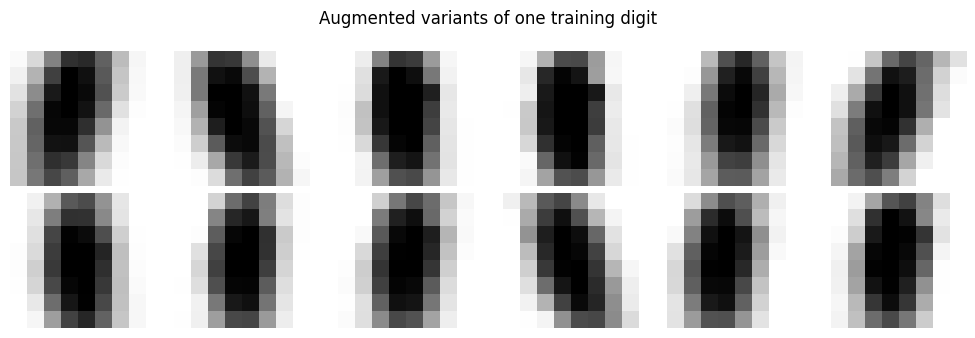

In [2]:
digits = load_digits()
images = (digits.images / 16.0).astype('float32')[..., np.newaxis]
labels = digits.target.astype('int64')

X_tr, X_tmp, y_tr, y_tmp = train_test_split(images, labels, test_size=0.3, stratify=labels, random_state=7)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=7)
print(f"train={len(y_tr)}  val={len(y_val)}  test={len(y_te)}")

data_augmentation = keras.Sequential([
    keras.layers.RandomRotation(0.06),
    keras.layers.RandomTranslation(0.08, 0.08),
    keras.layers.RandomZoom(0.08),
], name='augmentation')

fig, axes = plt.subplots(2, 6, figsize=(10, 3.4))
sample = X_tr[:1]
for ax in axes.ravel():
    aug = data_augmentation(sample, training=True)[0, ..., 0]
    ax.imshow(aug, cmap='gray_r'); ax.axis('off')
plt.suptitle('Augmented variants of one training digit'); plt.tight_layout()
plt.savefig('cv_augmentation_samples.png', dpi=110); plt.show()


## 2. Build a deeper CNN with batch normalization

In [3]:
def conv_block(x, filters):
    x = keras.layers.Conv2D(filters, 3, padding='same')(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Activation('relu')(x)
    return x

inputs = keras.Input(shape=(8, 8, 1))
x = data_augmentation(inputs)
x = conv_block(x, 32)
x = conv_block(x, 32)
x = keras.layers.MaxPooling2D(2)(x)
x = conv_block(x, 64)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dense(64, activation='relu')(x)
x = keras.layers.Dropout(0.3)(x)
outputs = keras.layers.Dense(10)(x)

model = keras.Model(inputs, outputs, name='advanced_cnn')
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])
model.summary()


Model: "advanced_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 8, 8, 1)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 8, 8, 1)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 8, 8, 32)       │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 8, 8, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 8, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 4, 4, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 4, 4, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,386 (130.41 KB)

 Trainable params: 33,130 (129.41 KB)

 Non-trainable params: 256 (1.00 KB)

## 3. Train with callbacks (early stopping + LR reduction on plateau)

Stopped after 41 epochs (best val_loss restored via EarlyStopping)


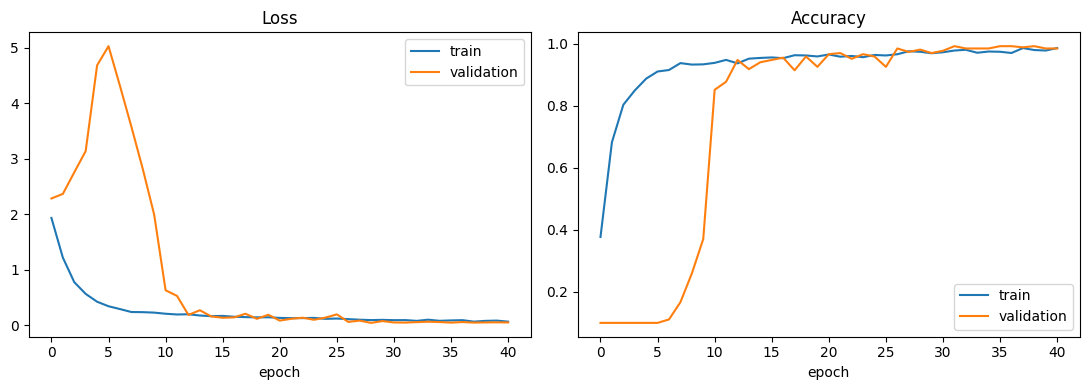

In [4]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5),
]

history = model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                     epochs=80, batch_size=32, callbacks=callbacks, verbose=0)
print(f"Stopped after {len(history.history['loss'])} epochs "
      f"(best val_loss restored via EarlyStopping)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history['loss'], label='train'); ax[0].plot(history.history['val_loss'], label='validation')
ax[0].set_title('Loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(history.history['accuracy'], label='train'); ax[1].plot(history.history['val_accuracy'], label='validation')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout(); plt.savefig('cv_training_curves.png', dpi=110); plt.show()


## 4. Evaluate on the test set

Test loss = 0.1086 | Test accuracy = 0.9630



               precision    recall  f1-score   support

           0      1.000     1.000     1.000        27
           1      0.957     0.786     0.863        28
           2      1.000     1.000     1.000        26
           3      0.929     0.963     0.945        27
           4      1.000     0.963     0.981        27
           5      0.933     1.000     0.966        28
           6      1.000     1.000     1.000        27
           7      1.000     1.000     1.000        27
           8      0.839     1.000     0.912        26
           9      1.000     0.926     0.962        27

    accuracy                          0.963       270
   macro avg      0.966     0.964     0.963       270
weighted avg      0.966     0.963     0.963       270



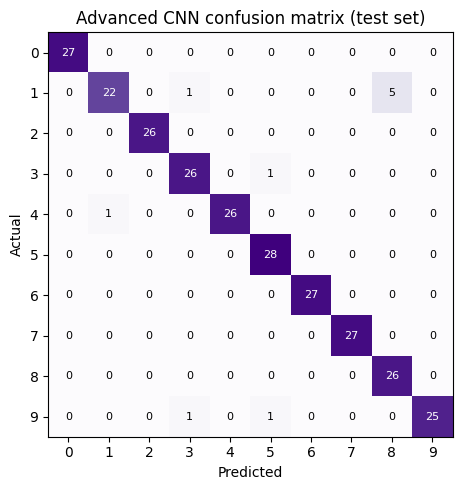

Saved -> advanced_cnn_digits.keras


In [5]:
test_loss, test_acc = model.evaluate(X_te, y_te, verbose=0)
print(f"Test loss = {test_loss:.4f} | Test accuracy = {test_acc:.4f}")

pred = model.predict(X_te, verbose=0).argmax(axis=1)
print("\n", classification_report(y_te, pred, digits=3))

cm = confusion_matrix(y_te, pred)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.imshow(cm, cmap='Purples')
ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8, color='white' if cm[i, j] > cm.max()/2 else 'black')
ax.set_title('Advanced CNN confusion matrix (test set)')
plt.tight_layout(); plt.savefig('cv_confusion_matrix.png', dpi=110); plt.show()

model.save('advanced_cnn_digits.keras')
print("Saved -> advanced_cnn_digits.keras")


## Summary

This project adds four techniques beyond the baseline CNN in Task 3.1: **data augmentation** (random
rotation/translation/zoom applied only during training, inside the model graph so it's automatic at
inference time), **batch normalization** after every convolution for more stable training, a
**global-average-pooling** head instead of flattening (fewer parameters, less prone to overfitting), and
**callbacks** that stop training once validation loss stops improving and shrink the learning rate on a
plateau rather than relying on a fixed epoch count. On this already-easy, low-resolution dataset the
accuracy gain over the 3.1 baseline is small, but these are the standard techniques that matter far more
on larger, noisier real-world image sets — including histopathology tiles, where augmentation and
regularization are often essential rather than optional.